In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import ttest_ind
from sklearn.linear_model import LinearRegression

from ics26_experiments import ICS26_DIR

/home/prajwal/github-repos/knnsur/src/__init__.py:17: UserWarning: CuPy not available; GPU acceleration will be disabled.
  warnings.warn(msg)


In [ ]:
subdirs = [d.name for d in ICS26_DIR.iterdir() if d.is_dir()]
print(subdirs)

['adaptive_clustering_global_vs_local', 'adaptive_clustering_global_vs_n_init_clusters', 'adaptive_clustering_global_local_vs_min_pts_per_cluster', 'shrinkage_analysis', 'ellipsoidal_knn_containment', 'rosenbrock_convergence_with_containment']


In [ ]:
# Publication-Quality Plot Settings
plt.rcParams.update(
    {
        "text.usetex": True,
        "font.family": "serif",
        "font.size": 10,
        "axes.labelsize": 11,
        "axes.titlesize": 12,
        "xtick.labelsize": 9,
        "ytick.labelsize": 9,
        "legend.fontsize": 9,
        "figure.figsize": (6.5, 4.5),
        "figure.dpi": 100,
        "savefig.dpi": 300,
        "lines.linewidth": 1.5,
        "lines.markersize": 5,
        "axes.grid": True,
        "grid.alpha": 0.3,
        "axes.axisbelow": True,
    }
)
PALETTE = "deep"
COLORS = sns.color_palette(PALETTE)

# Adaptive Clustering: Global vs Local Error Type

In [ ]:
adaptive_clustering_dir = ICS26_DIR / "adaptive_clustering_global_vs_local"
csv_path = adaptive_clustering_dir / "summary.csv"

df_ac_gl = pd.read_csv(csv_path)

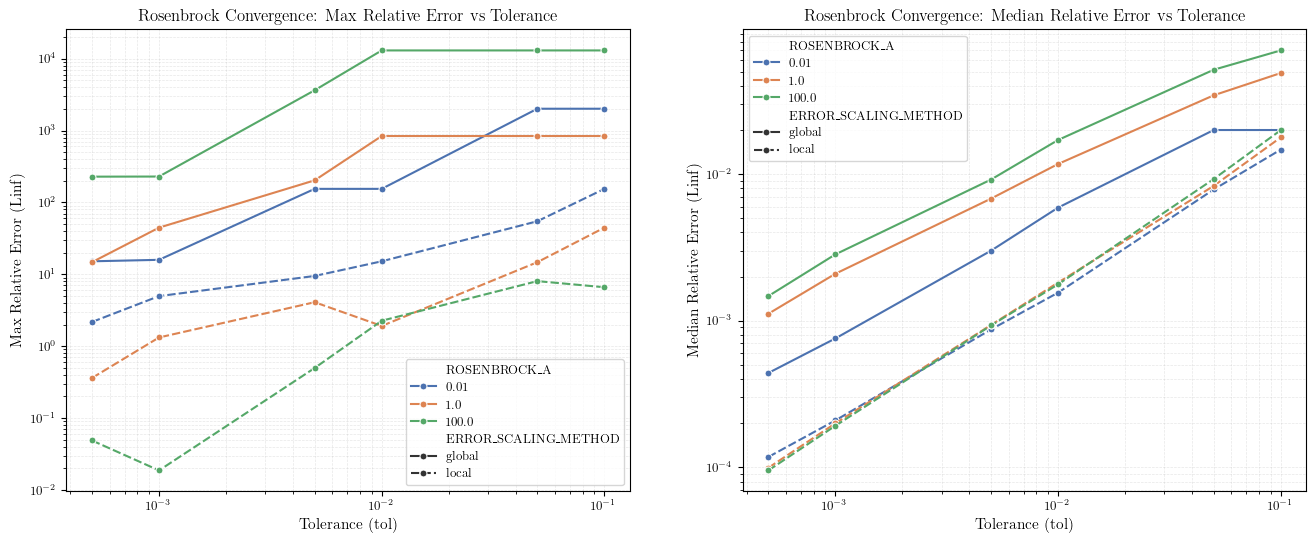

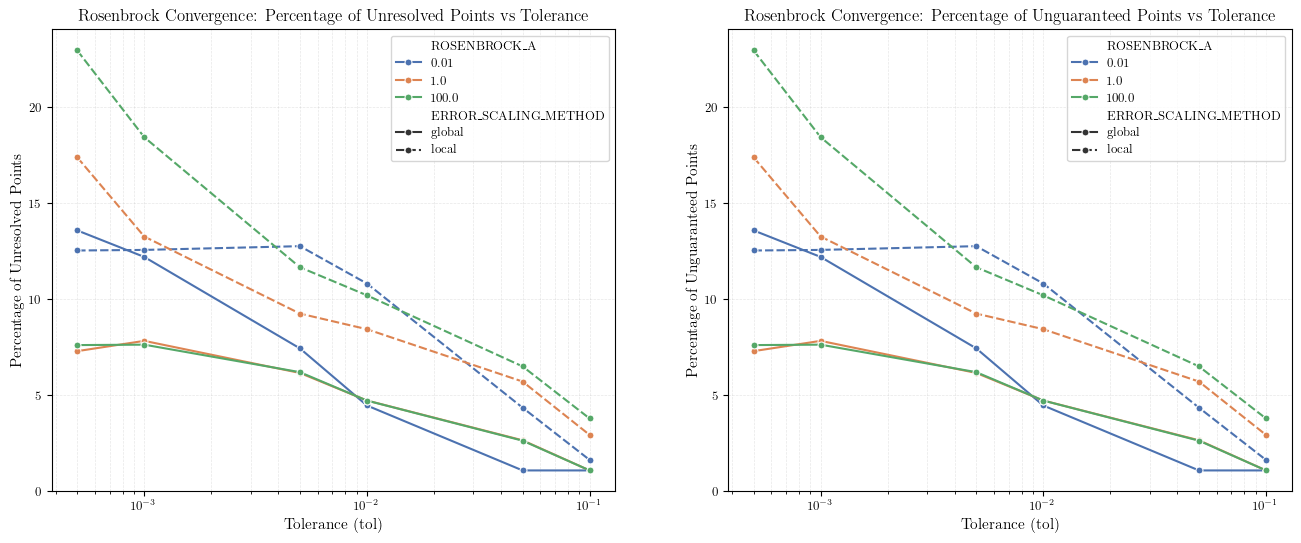

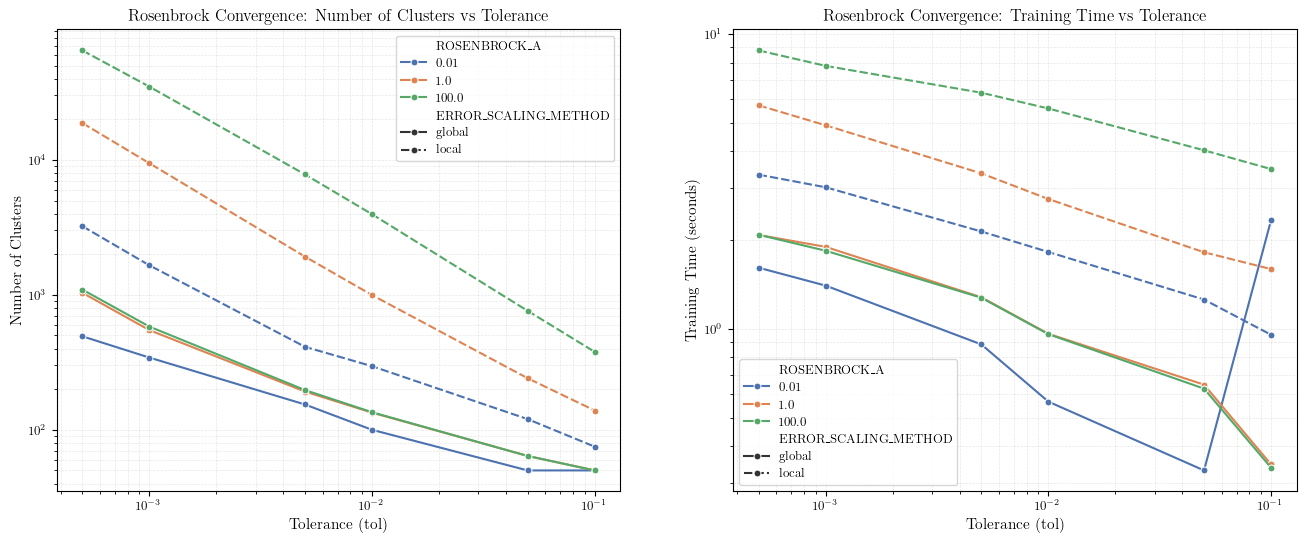

In [ ]:
plt.figure(figsize=(16, 6))
plt.subplot(1, 2, 1)
sns.lineplot(
    data=df_ac_gl,
    x="tol",
    y="max_rel_error_linf",
    style="ERROR_SCALING_METHOD",
    hue="ROSENBROCK_A",
    marker="o",
    palette=PALETTE,
)

plt.legend()
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Tolerance (tol)")
plt.ylabel("Max Relative Error (Linf)")
plt.title("Rosenbrock Convergence: Max Relative Error vs Tolerance")
plt.grid(True, which="both", ls="--", lw=0.5)

plt.subplot(1, 2, 2)
sns.lineplot(
    data=df_ac_gl,
    x="tol",
    y="median_rel_error_linf",
    style="ERROR_SCALING_METHOD",
    hue="ROSENBROCK_A",
    marker="o",
    palette=PALETTE,
)
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Tolerance (tol)")
plt.ylabel("Median Relative Error (Linf)")
plt.title("Rosenbrock Convergence: Median Relative Error vs Tolerance")
plt.grid(True, which="both", ls="--", lw=0.5)

# ====================================================
plt.figure(figsize=(16, 6))
plt.subplot(1, 2, 1)
sns.lineplot(
    data=df_ac_gl,
    x="tol",
    y="perct_unresolved",
    hue="ROSENBROCK_A",
    style="ERROR_SCALING_METHOD",
    marker="o",
    palette=PALETTE,
)
plt.xscale("log")
plt.xlabel("Tolerance (tol)")
plt.ylabel("Percentage of Unresolved Points")
plt.title("Rosenbrock Convergence: Percentage of Unresolved Points vs Tolerance")
plt.grid(True, which="both", ls="--", lw=0.5)

plt.subplot(1, 2, 2)
sns.lineplot(
    data=df_ac_gl,
    x="tol",
    y="perct_ungauranteed",
    hue="ROSENBROCK_A",
    style="ERROR_SCALING_METHOD",
    marker="o",
    palette=PALETTE,
)
plt.xscale("log")
plt.xlabel("Tolerance (tol)")
plt.ylabel("Percentage of Unguaranteed Points")
plt.title("Rosenbrock Convergence: Percentage of Unguaranteed Points vs Tolerance")
plt.grid(True, which="both", ls="--", lw=0.5)
# ====================================================

plt.figure(figsize=(16, 6))
plt.subplot(1, 2, 1)
sns.lineplot(
    data=df_ac_gl,
    x="tol",
    y="n_clusters",
    style="ERROR_SCALING_METHOD",
    hue="ROSENBROCK_A",
    marker="o",
    palette=PALETTE,
)

plt.legend()
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Tolerance (tol)")
plt.ylabel("Number of Clusters")
plt.title("Rosenbrock Convergence: Number of Clusters vs Tolerance")
plt.grid(True, which="both", ls="--", lw=0.5)

plt.subplot(1, 2, 2)
sns.lineplot(
    data=df_ac_gl,
    x="tol",
    y="train_time_sec",
    style="ERROR_SCALING_METHOD",
    hue="ROSENBROCK_A",
    marker="o",
    palette=PALETTE,
)
plt.legend()
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Tolerance (tol)")
plt.ylabel("Training Time (seconds)")
plt.title("Rosenbrock Convergence: Training Time vs Tolerance")
plt.grid(True, which="both", ls="--", lw=0.5)

### Comparing Means of max_rel_error_linf for global vs local (varying Rosenbrock A)

In [ ]:
err_col = "max_rel_error_linf"
global_array = df_ac_gl[df_ac_gl["ERROR_SCALING_METHOD"] == "global"][err_col]
local_array = df_ac_gl[df_ac_gl["ERROR_SCALING_METHOD"] == "local"][err_col]

t_stat, p_val = ttest_ind(global_array, local_array)
print(f"T-stat: {t_stat:.1e}, p-val: {p_val*100:.1f}%")

T-stat: 2.5e+00, p-val: 1.9%


### Comparing Means of n_clusters for global vs local (varying Rosenbrock A)

In [ ]:
cluster_col = "n_clusters"
global_array = df_ac_gl[df_ac_gl["ERROR_SCALING_METHOD"] == "global"][cluster_col]
local_array = df_ac_gl[df_ac_gl["ERROR_SCALING_METHOD"] == "local"][cluster_col]

t_stat, p_val = ttest_ind(global_array, local_array)
print(f"T-stat: {t_stat:.1e}, p-val: {p_val*100:.1f}%")

T-stat: -2.0e+00, p-val: 4.8%


# Adaptive Clustering: Variation of Num of Initial CLusters

In [ ]:
ac_n_init_dir = ICS26_DIR / "adaptive_clustering_global_vs_n_init_clusters"
csv_path = ac_n_init_dir / "summary.csv"

df_ac_ninit = pd.read_csv(csv_path)
df_ac_ninit["ROSENBROCK_DIM_A_ERR"] = (
    df_ac_ninit["dim"].astype(str)
    + "D_"
    + df_ac_ninit["ROSENBROCK_A"].astype(str)
    + "A_"
    + df_ac_ninit["ERROR_SCALING_METHOD"].astype(str)
)

# drop rows where N_INIT_CLUSTERS is [125, 625]
df_ac_ninit = df_ac_ninit[~df_ac_ninit["N_INIT_CLUSTERS"].isin([5, 125, 625])]

,N_INIT_CLUSTERS,max_rel_error_linf,median_rel_error_linf,perct_ungauranteed,n_clusters,num_levels,train_time_sec
N_INIT_CLUSTERS,1.0,-0.137145,-0.254417,0.064694,-0.006607,-0.346287,-0.199818


Text(0.5, 1.0, 'Correlation Heatmap: Varying N_INIT_CLUSTERS')

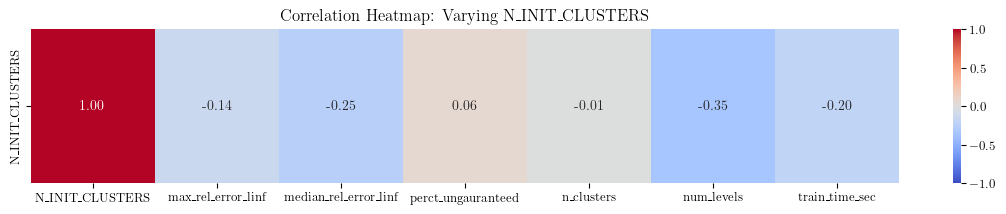

In [ ]:
cols = [
    "N_INIT_CLUSTERS",
    "max_rel_error_linf",
    "median_rel_error_linf",
    "perct_ungauranteed",
    "n_clusters",
    "num_levels",
    "train_time_sec",
]
corr_df = df_ac_ninit[cols].corr()
corr_df_first_row = corr_df.iloc[[0], :]  # Select only first row
display(corr_df_first_row)

plt.figure(figsize=(14, 2))
sns.heatmap(corr_df_first_row, annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1)
plt.title("Correlation Heatmap: Varying N_INIT_CLUSTERS")

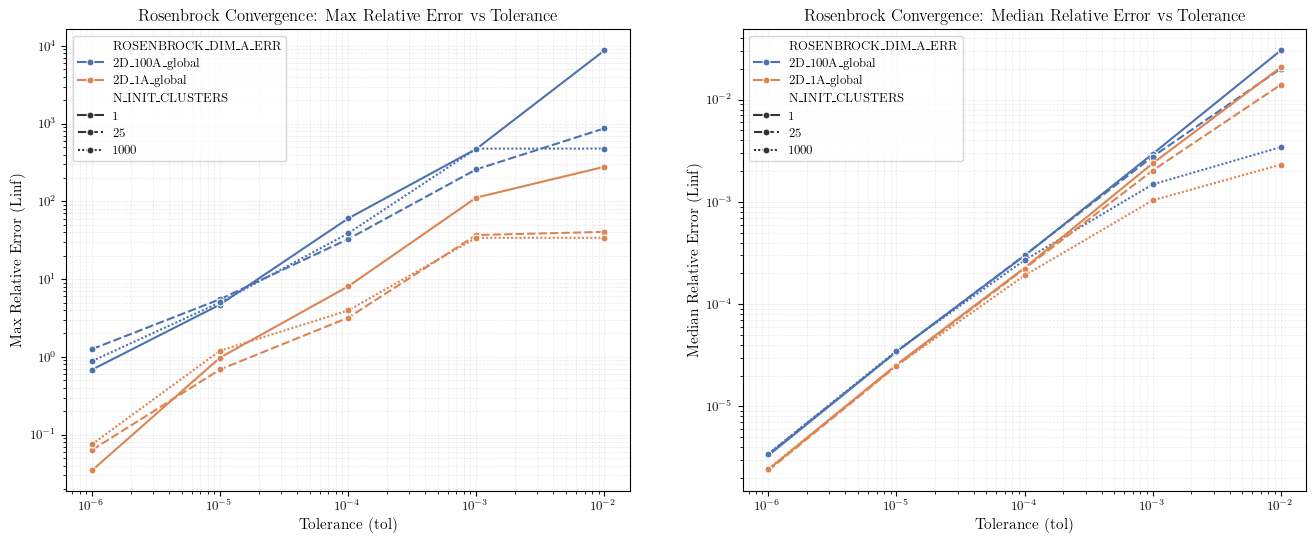

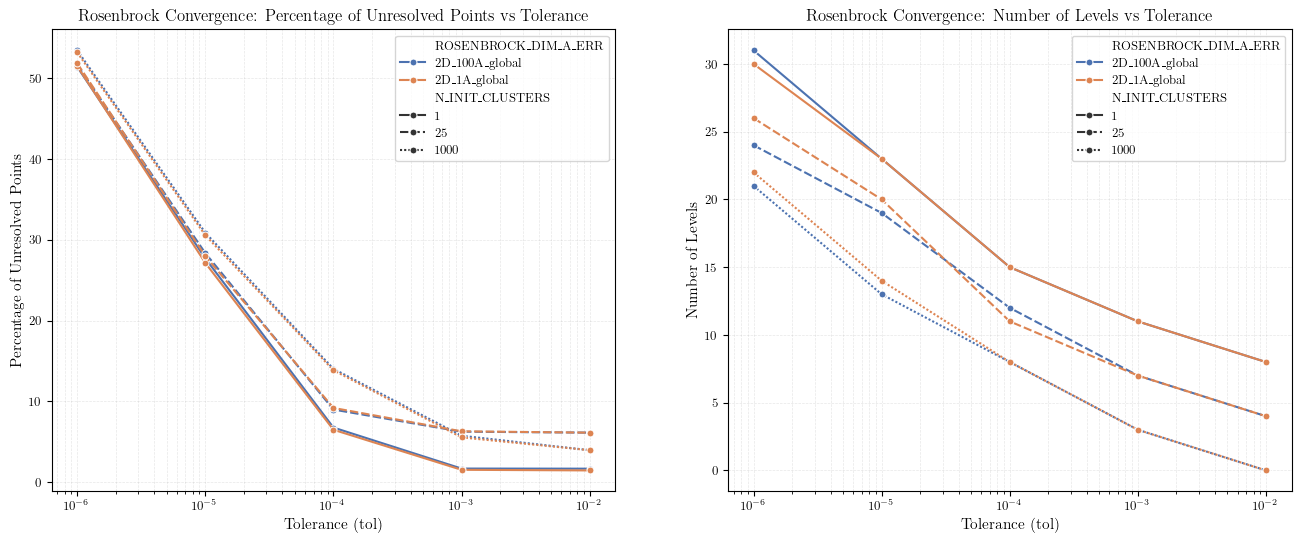

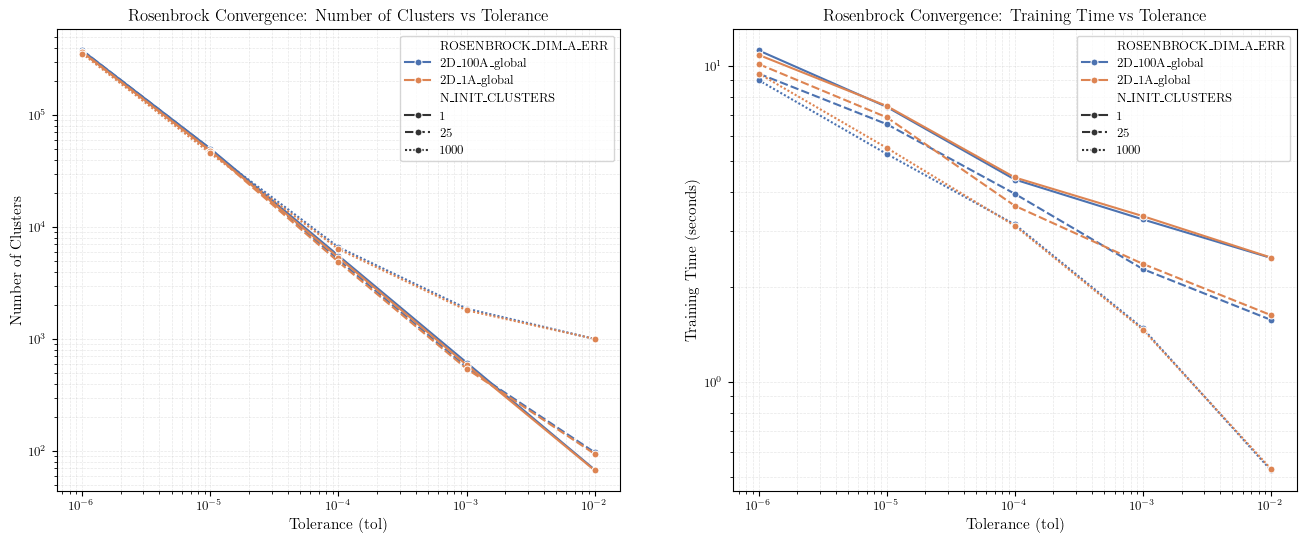

In [ ]:
plt.figure(figsize=(16, 6))
plt.subplot(1, 2, 1)
sns.lineplot(
    data=df_ac_ninit,
    x="tol",
    y="max_rel_error_linf",
    style="N_INIT_CLUSTERS",
    hue="ROSENBROCK_DIM_A_ERR",
    marker="o",
    palette=PALETTE,
)

plt.legend()
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Tolerance (tol)")
plt.ylabel("Max Relative Error (Linf)")
plt.title("Rosenbrock Convergence: Max Relative Error vs Tolerance")
plt.grid(True, which="both", ls="--", lw=0.5)

plt.subplot(1, 2, 2)
sns.lineplot(
    data=df_ac_ninit,
    x="tol",
    y="median_rel_error_linf",
    style="N_INIT_CLUSTERS",
    hue="ROSENBROCK_DIM_A_ERR",
    marker="o",
    palette=PALETTE,
)
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Tolerance (tol)")
plt.ylabel("Median Relative Error (Linf)")
plt.title("Rosenbrock Convergence: Median Relative Error vs Tolerance")
plt.grid(True, which="both", ls="--", lw=0.5)

# ====================================================
plt.figure(figsize=(16, 6))
plt.subplot(1, 2, 1)
sns.lineplot(
    data=df_ac_ninit,
    x="tol",
    y="perct_unresolved",
    hue="ROSENBROCK_DIM_A_ERR",
    style="N_INIT_CLUSTERS",
    marker="o",
    palette=PALETTE,
)
plt.xscale("log")
plt.xlabel("Tolerance (tol)")
plt.ylabel("Percentage of Unresolved Points")
plt.title("Rosenbrock Convergence: Percentage of Unresolved Points vs Tolerance")
plt.grid(True, which="both", ls="--", lw=0.5)

plt.subplot(1, 2, 2)
sns.lineplot(
    data=df_ac_ninit,
    x="tol",
    y="num_levels",
    hue="ROSENBROCK_DIM_A_ERR",
    style="N_INIT_CLUSTERS",
    marker="o",
    palette=PALETTE,
)
plt.xscale("log")
plt.xlabel("Tolerance (tol)")
plt.ylabel("Number of Levels")
plt.title("Rosenbrock Convergence: Number of Levels vs Tolerance")
plt.grid(True, which="both", ls="--", lw=0.5)
# ====================================================

plt.figure(figsize=(16, 6))
plt.subplot(1, 2, 1)
sns.lineplot(
    data=df_ac_ninit,
    x="tol",
    y="n_clusters",
    style="N_INIT_CLUSTERS",
    hue="ROSENBROCK_DIM_A_ERR",
    marker="o",
    palette=PALETTE,
)

plt.legend()
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Tolerance (tol)")
plt.ylabel("Number of Clusters")
plt.title("Rosenbrock Convergence: Number of Clusters vs Tolerance")
plt.grid(True, which="both", ls="--", lw=0.5)

plt.subplot(1, 2, 2)
sns.lineplot(
    data=df_ac_ninit,
    x="tol",
    y="train_time_sec",
    style="N_INIT_CLUSTERS",
    hue="ROSENBROCK_DIM_A_ERR",
    marker="o",
    palette=PALETTE,
)
plt.legend()
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Tolerance (tol)")
plt.ylabel("Training Time (seconds)")
plt.title("Rosenbrock Convergence: Training Time vs Tolerance")
plt.grid(True, which="both", ls="--", lw=0.5)

# Adaptive Clustering: Variation of Min Points per Cluster

[  25  625 1000    5  125]
[625   5 125]


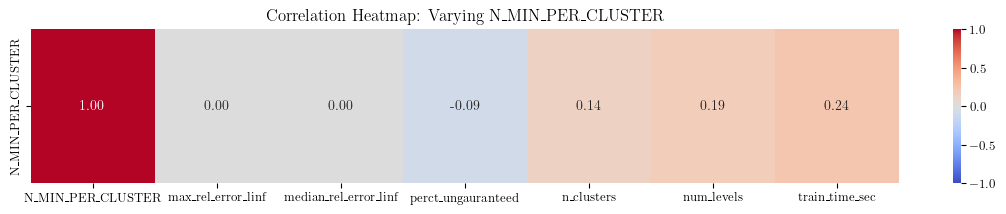

In [ ]:
ac_mppc = ICS26_DIR / "adaptive_clustering_global_local_vs_min_pts_per_cluster"
csv_path = ac_mppc / "summary.csv"

df_ac_mppc = pd.read_csv(csv_path)
df_ac_mppc["ROSENBROCK_DIM_A_ERR"] = (
    df_ac_mppc["dim"].astype(str)
    + "D_"
    + df_ac_mppc["ROSENBROCK_A"].astype(str)
    + "A_"
    + df_ac_mppc["ERROR_SCALING_METHOD"].astype(str)
)

print(df_ac_mppc["N_MIN_PER_CLUSTER"].unique())

cols = [
    "N_MIN_PER_CLUSTER",
    "max_rel_error_linf",
    "median_rel_error_linf",
    "perct_ungauranteed",
    "n_clusters",
    "num_levels",
    "train_time_sec",
]
corr_df = df_ac_mppc[cols].corr()
corr_df_first_row = corr_df.iloc[[0], :]  # Select only first row
plt.figure(figsize=(14, 2))
sns.heatmap(corr_df_first_row, annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1)
plt.title("Correlation Heatmap: Varying N_MIN_PER_CLUSTER")
df_ac_mppc = df_ac_mppc[df_ac_mppc["N_MIN_PER_CLUSTER"].isin([5, 125, 625])]
print(df_ac_mppc["N_MIN_PER_CLUSTER"].unique())

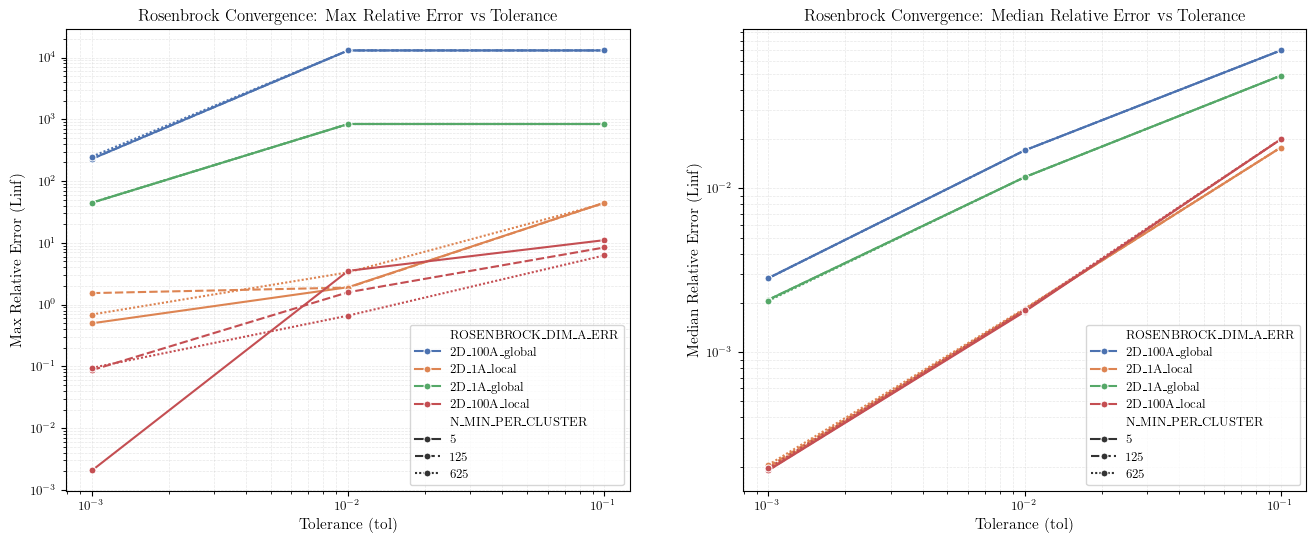

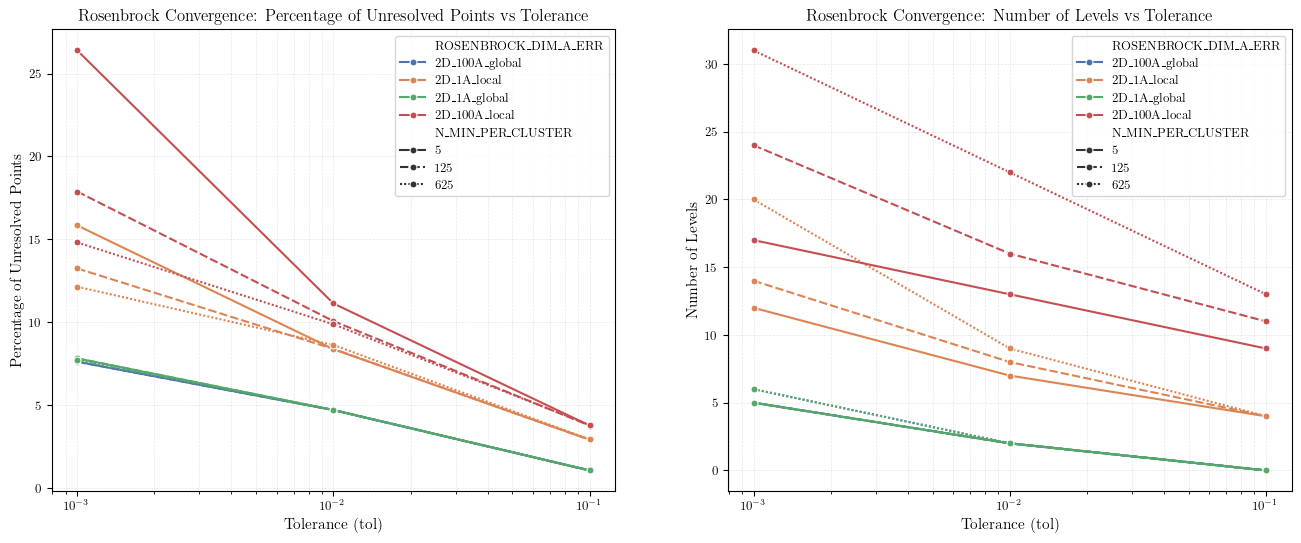

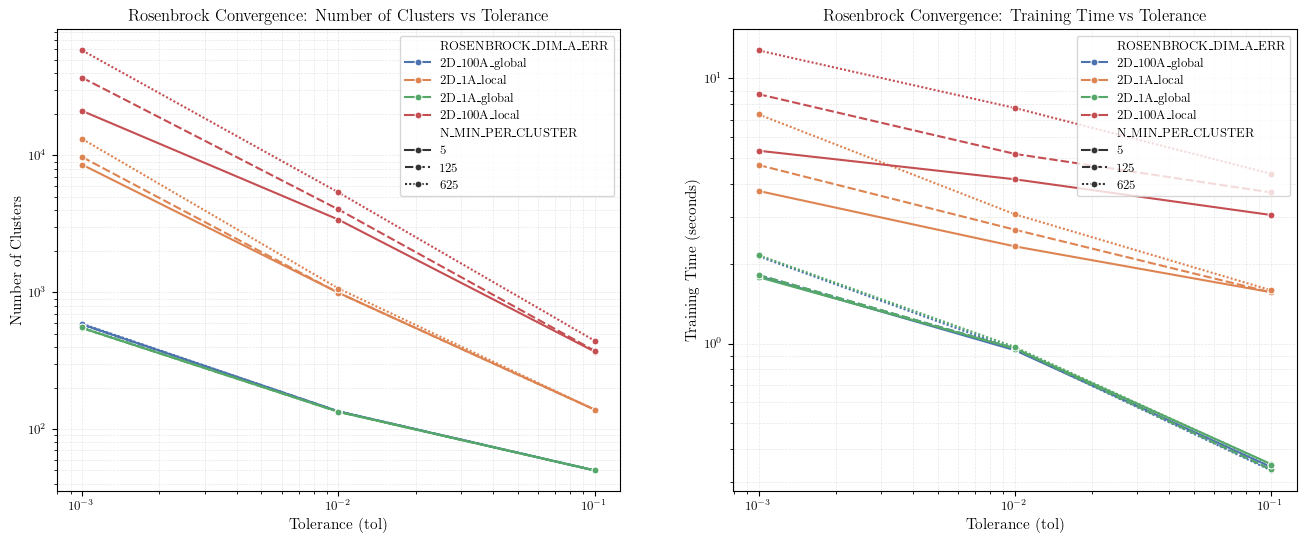

In [ ]:
plt.figure(figsize=(16, 6))
plt.subplot(1, 2, 1)
sns.lineplot(
    data=df_ac_mppc,
    x="tol",
    y="max_rel_error_linf",
    hue="ROSENBROCK_DIM_A_ERR",
    style="N_MIN_PER_CLUSTER",
    marker="o",
    palette=PALETTE,
)

plt.legend()
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Tolerance (tol)")
plt.ylabel("Max Relative Error (Linf)")
plt.title("Rosenbrock Convergence: Max Relative Error vs Tolerance")
plt.grid(True, which="both", ls="--", lw=0.5)

plt.subplot(1, 2, 2)
sns.lineplot(
    data=df_ac_mppc,
    x="tol",
    y="median_rel_error_linf",
    hue="ROSENBROCK_DIM_A_ERR",
    style="N_MIN_PER_CLUSTER",
    marker="o",
    palette=PALETTE,
)
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Tolerance (tol)")
plt.ylabel("Median Relative Error (Linf)")
plt.title("Rosenbrock Convergence: Median Relative Error vs Tolerance")
plt.grid(True, which="both", ls="--", lw=0.5)

# ====================================================
plt.figure(figsize=(16, 6))
plt.subplot(1, 2, 1)
sns.lineplot(
    data=df_ac_mppc,
    x="tol",
    y="perct_unresolved",
    hue="ROSENBROCK_DIM_A_ERR",
    style="N_MIN_PER_CLUSTER",
    marker="o",
    palette=PALETTE,
)
plt.xscale("log")
plt.xlabel("Tolerance (tol)")
plt.ylabel("Percentage of Unresolved Points")
plt.title("Rosenbrock Convergence: Percentage of Unresolved Points vs Tolerance")
plt.grid(True, which="both", ls="--", lw=0.5)

plt.subplot(1, 2, 2)
sns.lineplot(
    data=df_ac_mppc,
    x="tol",
    y="num_levels",
    hue="ROSENBROCK_DIM_A_ERR",
    style="N_MIN_PER_CLUSTER",
    marker="o",
    palette=PALETTE,
)
plt.xscale("log")
plt.xlabel("Tolerance (tol)")
plt.ylabel("Number of Levels")
plt.title("Rosenbrock Convergence: Number of Levels vs Tolerance")
plt.grid(True, which="both", ls="--", lw=0.5)
# ====================================================

plt.figure(figsize=(16, 6))
plt.subplot(1, 2, 1)
sns.lineplot(
    data=df_ac_mppc,
    x="tol",
    y="n_clusters",
    hue="ROSENBROCK_DIM_A_ERR",
    style="N_MIN_PER_CLUSTER",
    marker="o",
    palette=PALETTE,
)

plt.legend()
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Tolerance (tol)")
plt.ylabel("Number of Clusters")
plt.title("Rosenbrock Convergence: Number of Clusters vs Tolerance")
plt.grid(True, which="both", ls="--", lw=0.5)

plt.subplot(1, 2, 2)
sns.lineplot(
    data=df_ac_mppc,
    x="tol",
    y="train_time_sec",
    hue="ROSENBROCK_DIM_A_ERR",
    style="N_MIN_PER_CLUSTER",
    marker="o",
    palette=PALETTE,
)
plt.legend()
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Tolerance (tol)")
plt.ylabel("Training Time (seconds)")
plt.title("Rosenbrock Convergence: Training Time vs Tolerance")
plt.grid(True, which="both", ls="--", lw=0.5)

# Ellipsoidal KNN Containment EDAA

In [ ]:
ellipsoidal_dir = ICS26_DIR / "ellipsoidal_knn_containment"
csv_path = ellipsoidal_dir / "summary.csv"

df_ellipsoidal_knn = pd.read_csv(csv_path)

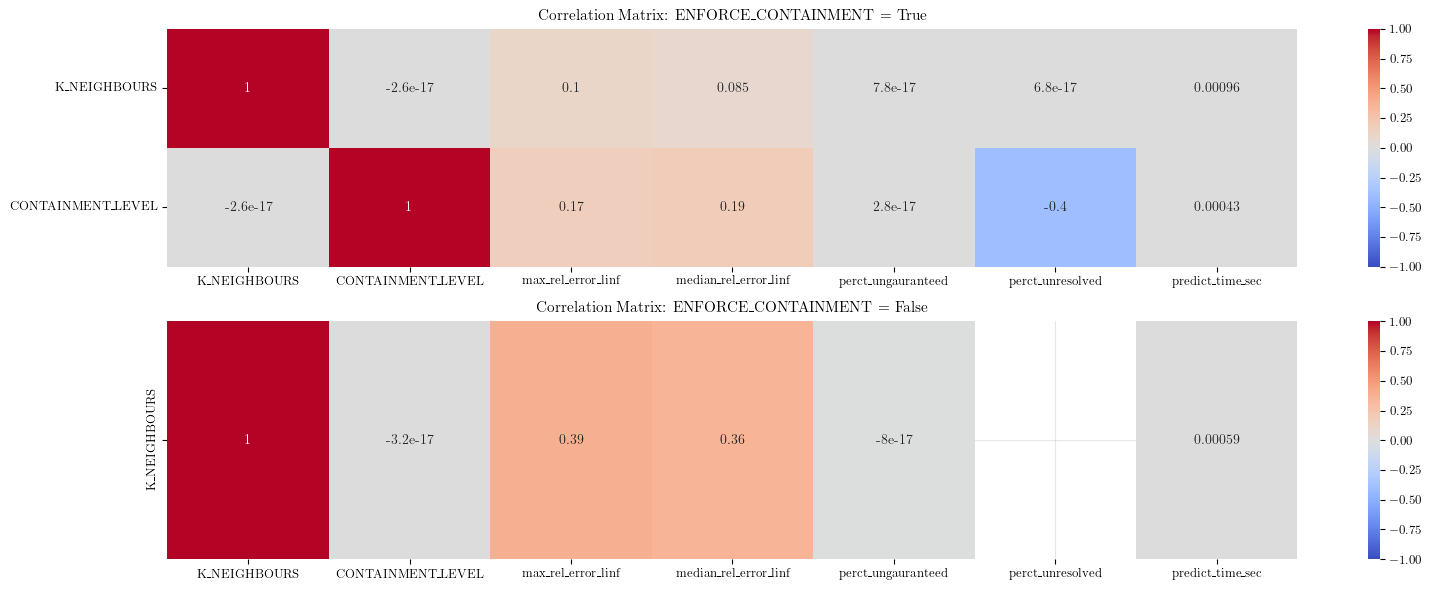

In [ ]:
cols = [
    "K_NEIGHBOURS",
    "CONTAINMENT_LEVEL",
    "max_rel_error_linf",
    "median_rel_error_linf",
    "perct_ungauranteed",
    "perct_unresolved",
    "predict_time_sec",
]
trc_col = "ENFORCE_CONTAINMENT"
corr_df_constrained = df_ellipsoidal_knn[df_ellipsoidal_knn[trc_col] == True][cols]
corr_df_unconstrained = df_ellipsoidal_knn[df_ellipsoidal_knn[trc_col] == False][cols]

corr_constrained = corr_df_constrained.corr()
corr_unconstrained = corr_df_unconstrained.corr()
corr_const_selected = corr_constrained.iloc[[0, 1], :]  # Select 1,2 row
corr_uncost_selected = corr_unconstrained.iloc[[0], :]  # Select 1,2 row

plt.figure(figsize=(16, 6))
plt.subplot(2, 1, 1)
sns.heatmap(corr_const_selected, annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title(f"Correlation Matrix: {trc_col} = True", fontsize=11)
plt.subplot(2, 1, 2)
sns.heatmap(corr_uncost_selected, annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title(f"Correlation Matrix: {trc_col} = False", fontsize=11)
plt.tight_layout()

### Testing means of max_rel_error_linf for constrained vs unconstrained (CL=1)

In [ ]:
conds = df_ellipsoidal_knn["CONTAINMENT_LEVEL"] == 1
max_rel_error_linf_constrained = df_ellipsoidal_knn[
    conds & (df_ellipsoidal_knn[trc_col] == True)
][err_col]
max_rel_error_linf_unconstrained = df_ellipsoidal_knn[
    conds & (df_ellipsoidal_knn[trc_col] == False)
][err_col]

t_stat, p_val = ttest_ind(
    max_rel_error_linf_constrained, max_rel_error_linf_unconstrained
)
mean_1 = max_rel_error_linf_constrained.mean()
mean_2 = max_rel_error_linf_unconstrained.mean()
print(f"Means: {mean_1:.2f} (constrained, CL=1) vs {mean_2:.2f} (unconstrained, CL=1)")
print(f"T-statistic: {t_stat}, P-value: {p_val*100:.2f}%")  # type: ignore

Means: 2666.03 (constrained, CL=1) vs 13363.57 (unconstrained, CL=1)
T-statistic: -1.7458866919502831, P-value: 8.61%


### Testing means of max_rel_error_linf for CL = 1 vs CL = 2 (constrained)

In [ ]:
err_col = "max_rel_error_linf"
conds = df_ellipsoidal_knn[trc_col] == True
max_rel_error_linf_cl1 = df_ellipsoidal_knn[
    conds & (df_ellipsoidal_knn["CONTAINMENT_LEVEL"] == 1)
][err_col]
max_rel_error_linf_cl2 = df_ellipsoidal_knn[
    conds & (df_ellipsoidal_knn["CONTAINMENT_LEVEL"] == 2)
][err_col]

t_stat, p_val = ttest_ind(max_rel_error_linf_cl1, max_rel_error_linf_cl2)
mean_1 = max_rel_error_linf_cl1.mean()
mean_2 = max_rel_error_linf_cl2.mean()
print(f"Means: {mean_1:.2f} (constrained, CL=1) vs {mean_2:.2f} (constrained, CL=2)")
print(f"T-statistic: {t_stat}, P-value: {p_val*100:.2f}%")  # type: ignore

Means: 2666.03 (constrained, CL=1) vs 4895.49 (constrained, CL=2)
T-statistic: -1.223452063216572, P-value: 22.61%


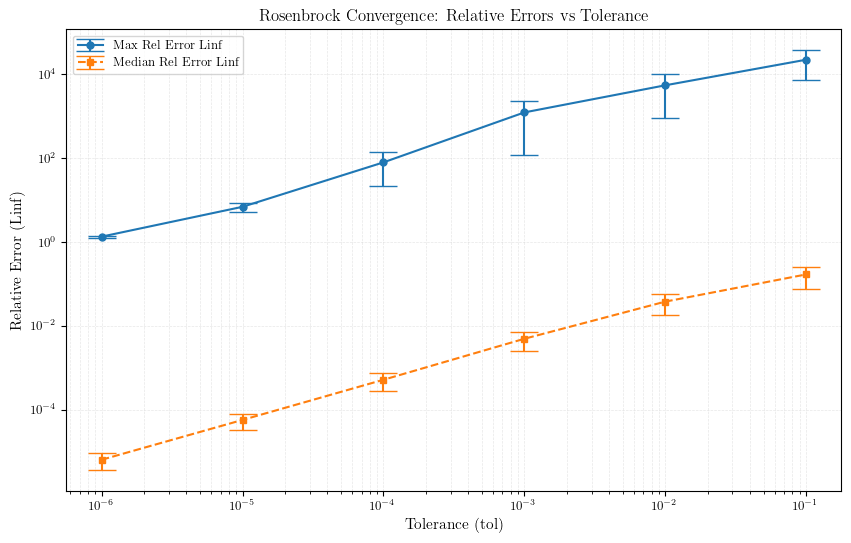

In [ ]:
cond = (df_ellipsoidal_knn[trc_col] == True) & (
    df_ellipsoidal_knn["CONTAINMENT_LEVEL"] <= 3
)

# Plot histograms of max_rel_error_linf, median_rel_error_linf for different tolerances
tols = sorted(df_ellipsoidal_knn[cond]["tol"].unique())
plt.figure(figsize=(10, 6))
data = []
for tol in tols:
    subset = df_ellipsoidal_knn[cond & (df_ellipsoidal_knn["tol"] == tol)][
        ["max_rel_error_linf", "median_rel_error_linf"]
    ]
    _mu, _std = subset.mean(), subset.std()
    data.append((tol, _mu, _std))

# unpack data - for each of max_rel_error_linf and median_rel_error_linf
tols, mus, stds = zip(*data)
max_means, max_stds = zip(
    *[(m["max_rel_error_linf"], s["max_rel_error_linf"]) for m, s in zip(mus, stds)]
)
median_means, median_stds = zip(
    *[
        (m["median_rel_error_linf"], s["median_rel_error_linf"])
        for m, s in zip(mus, stds)
    ]
)

plt.errorbar(
    tols, max_means, yerr=max_stds, fmt="o-", capsize=10, label="Max Rel Error Linf"
)
plt.errorbar(
    tols,
    median_means,
    yerr=median_stds,
    fmt="s--",
    capsize=10,
    label="Median Rel Error Linf",
)
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Tolerance (tol)")
plt.ylabel("Relative Error (Linf)")
plt.title("Rosenbrock Convergence: Relative Errors vs Tolerance")
plt.legend()
plt.grid(True, which="both", ls="--", lw=0.5)

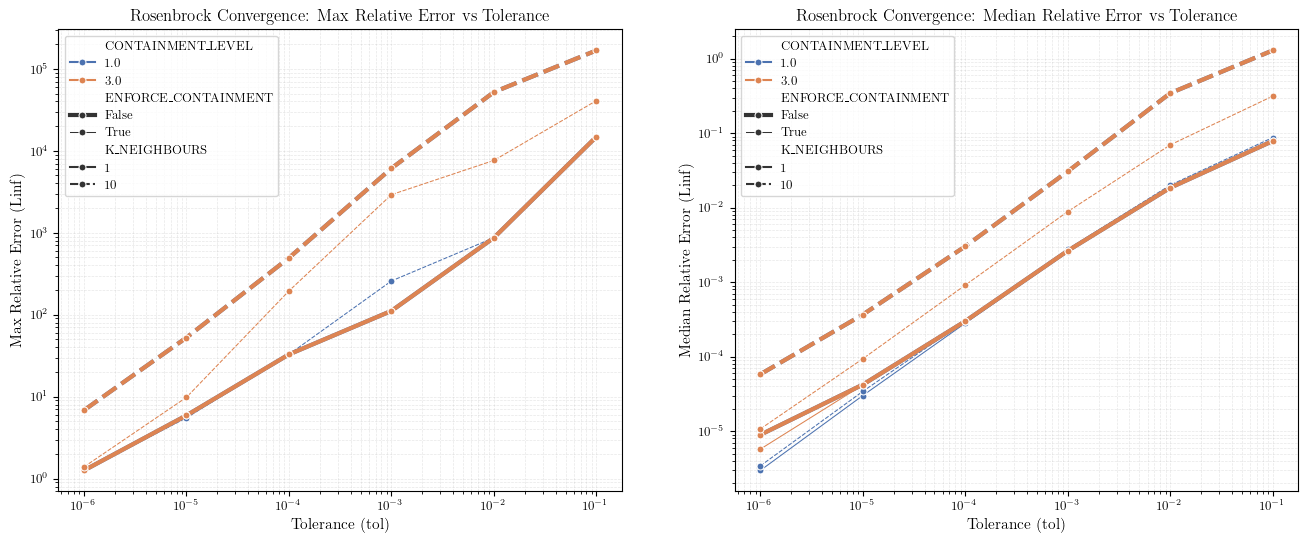

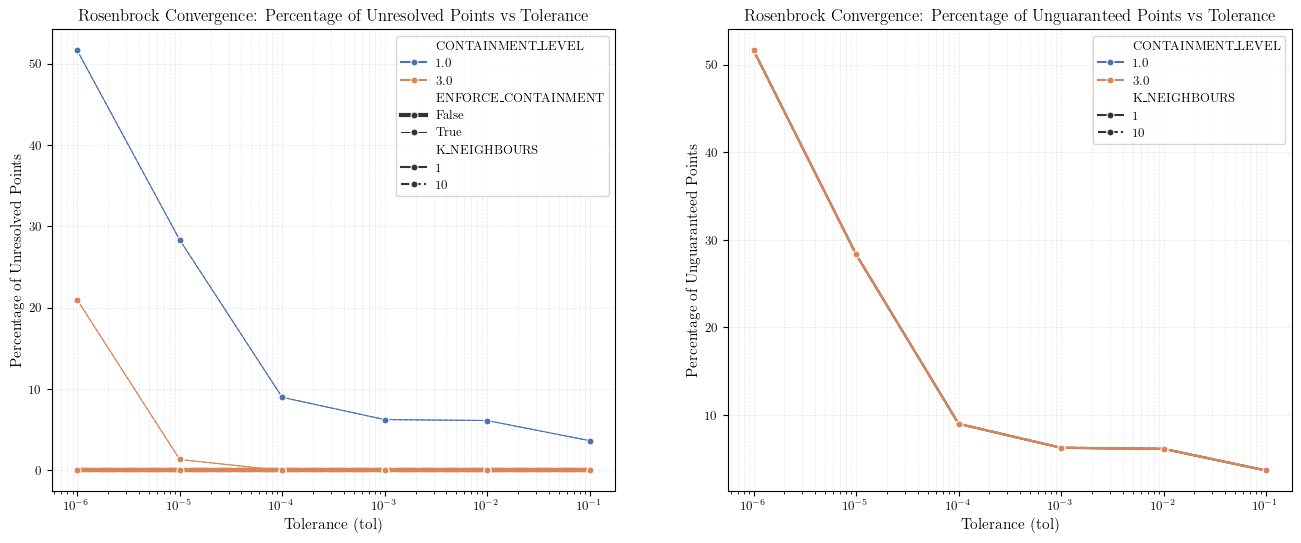

In [ ]:
cond = (
    df_ellipsoidal_knn["K_NEIGHBOURS"].isin([1, 10])
    & (df_ellipsoidal_knn["CONTAINMENT_LEVEL"].isin([1, 3]))
    # & (df_ellipsoidal_knn[trc_col] == True)
)
plt.figure(figsize=(16, 6))
plt.subplot(1, 2, 1)
sns.lineplot(
    data=df_ellipsoidal_knn[cond],
    x="tol",
    y="max_rel_error_linf",
    hue="CONTAINMENT_LEVEL",
    style="K_NEIGHBOURS",
    size=trc_col,
    marker="o",
    palette=PALETTE,
)

plt.legend()
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Tolerance (tol)")
plt.ylabel("Max Relative Error (Linf)")
plt.title("Rosenbrock Convergence: Max Relative Error vs Tolerance")
plt.grid(True, which="both", ls="--", lw=0.5)

plt.subplot(1, 2, 2)
sns.lineplot(
    data=df_ellipsoidal_knn[cond],
    x="tol",
    y="median_rel_error_linf",
    hue="CONTAINMENT_LEVEL",
    style="K_NEIGHBOURS",
    size=trc_col,
    marker="o",
    palette=PALETTE,
)
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Tolerance (tol)")
plt.ylabel("Median Relative Error (Linf)")
plt.title("Rosenbrock Convergence: Median Relative Error vs Tolerance")
plt.grid(True, which="both", ls="--", lw=0.5)

# ====================================================
plt.figure(figsize=(16, 6))
plt.subplot(1, 2, 1)
sns.lineplot(
    data=df_ellipsoidal_knn[cond],
    x="tol",
    y="perct_unresolved",
    hue="CONTAINMENT_LEVEL",
    style="K_NEIGHBOURS",
    size=trc_col,
    marker="o",
    palette=PALETTE,
)
plt.xscale("log")
plt.xlabel("Tolerance (tol)")
plt.ylabel("Percentage of Unresolved Points")
plt.title("Rosenbrock Convergence: Percentage of Unresolved Points vs Tolerance")
plt.grid(True, which="both", ls="--", lw=0.5)

plt.subplot(1, 2, 2)
sns.lineplot(
    data=df_ellipsoidal_knn[cond],
    x="tol",
    y="perct_ungauranteed",
    hue="CONTAINMENT_LEVEL",
    style="K_NEIGHBOURS",
    marker="o",
    palette=PALETTE,
)
plt.xscale("log")
plt.xlabel("Tolerance (tol)")
plt.ylabel("Percentage of Unguaranteed Points")
plt.title("Rosenbrock Convergence: Percentage of Unguaranteed Points vs Tolerance")
plt.grid(True, which="both", ls="--", lw=0.5)

## Insights
- The mean maximum relative error (L-infinity) is lower when `TRUST_REGION_CONTAINMENT` is enabled, as compared to when it is disabled (p-value ~ 0.06).
- When `TRUST_REGION_CONTAINMENT` is enabled, the mean maximum relative error (L-infinity) is lower for containment level 1 compared to containment level 2 (p-value ~ 0.03).
- With `TRUST_REGION_CONTAINMENT` enabled, and containment level set to 1, the `kNN` value does not significantly affect the maximum relative error (L-infinity)

# Rosenbrock Convergence (With containment) EDA 

In [ ]:
rosenbrock_dir = ICS26_DIR / "rosenbrock_convergence_with_containment"
csv_path = rosenbrock_dir / "summary.csv"

df_rb_with_cont = pd.read_csv(csv_path)

df_rb_with_cont["rosenbrock_DIM_A"] = (
    df_rb_with_cont["dim"].astype(str)
    + "D_"
    + df_rb_with_cont["ROSENBROCK_A"].astype(str)
    + "A"
)

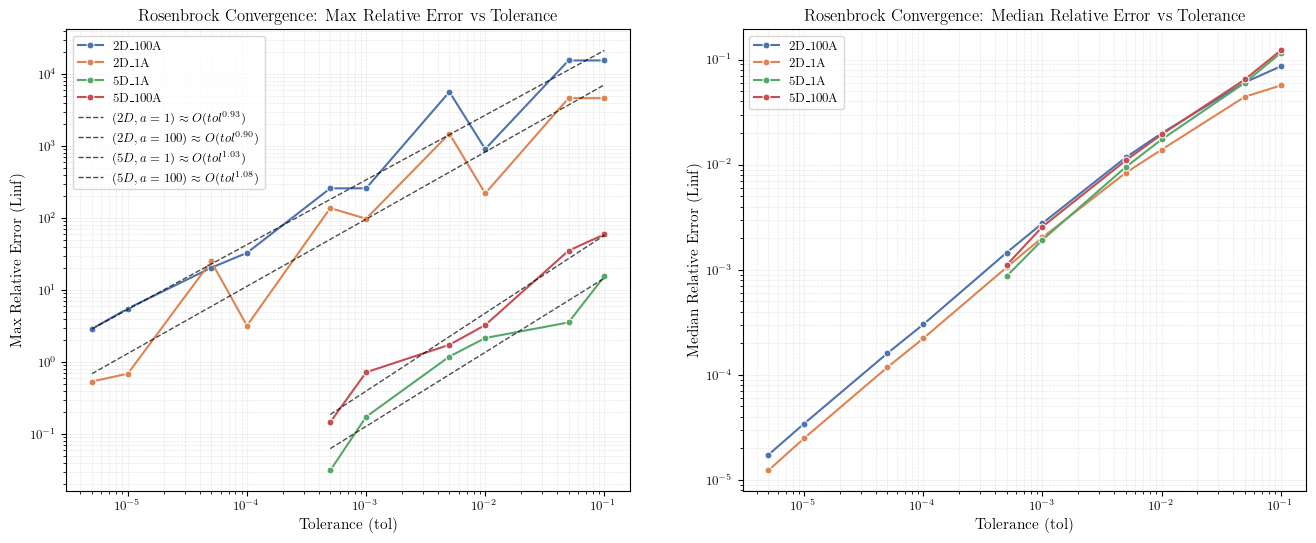

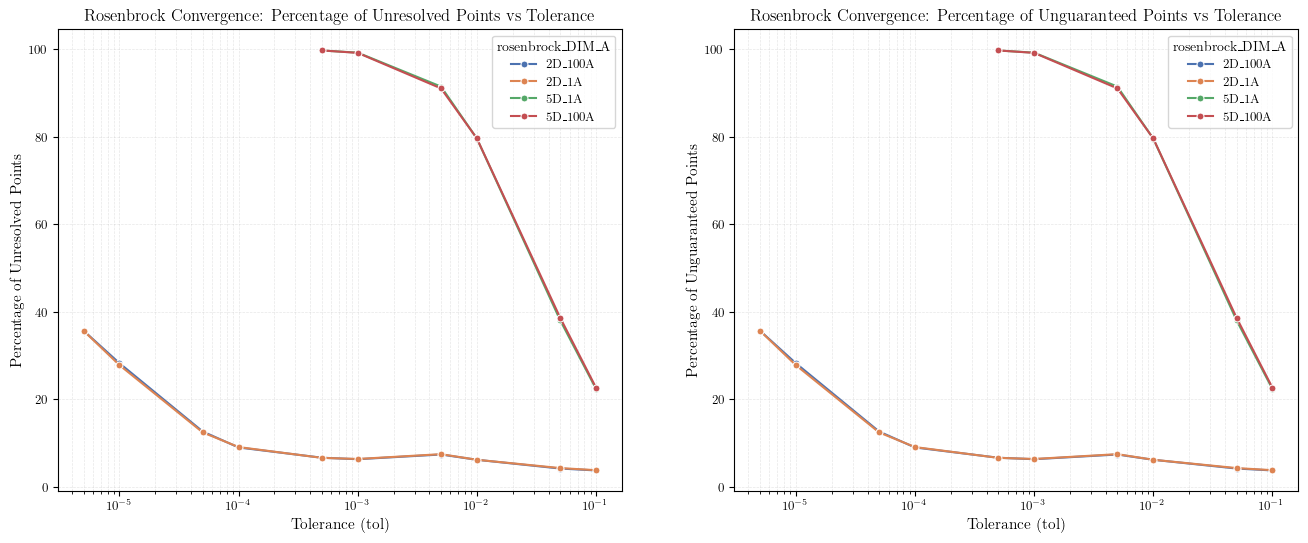

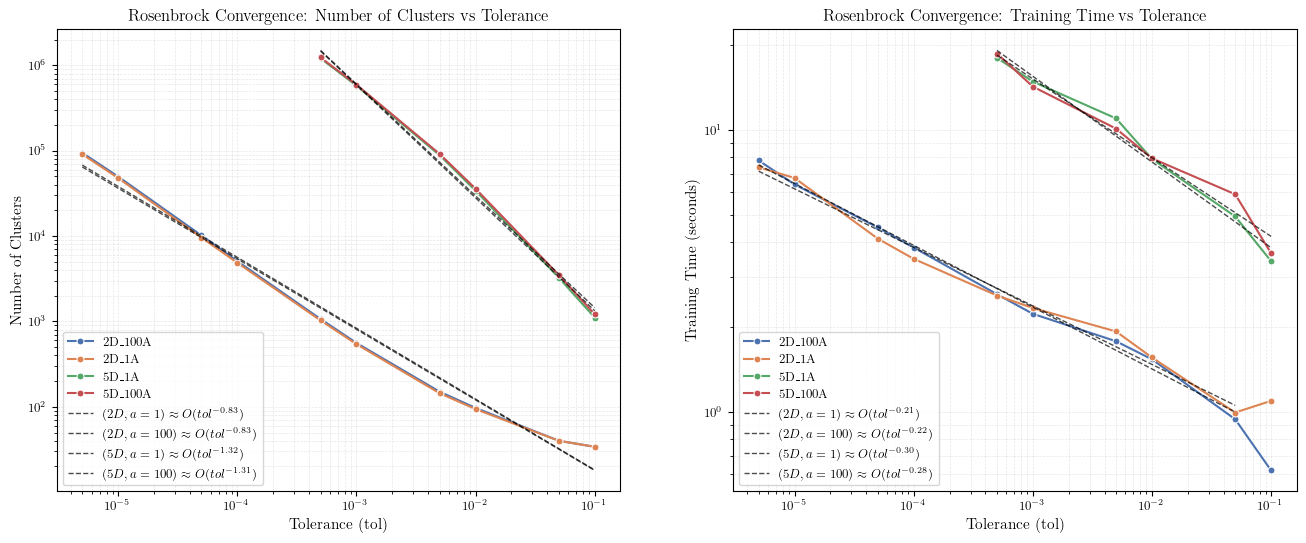

In [ ]:
plt.figure(figsize=(16, 6))
plt.subplot(1, 2, 1)
sns.lineplot(
    data=df_rb_with_cont,
    x="tol",
    y="max_rel_error_linf",
    hue="rosenbrock_DIM_A",
    marker="o",
    palette=PALETTE,
)

# Fit a line to each series to estimate convergence rate
for (dim, a_val), group in df_rb_with_cont.groupby(["dim", "ROSENBROCK_A"]):
    # Skip nan or inf values
    group = group.where(~group.isin([np.inf, -np.inf]), np.nan).dropna(
        subset=["max_rel_error_linf"]
    )
    if len(group) < 4:
        continue
    X = np.log(group["tol"]).values.reshape(-1, 1)
    y = np.log(group["max_rel_error_linf"]).values
    model = LinearRegression()
    model.fit(X, y)

    # Plot the fitted line
    x_fit = np.linspace(X.min(), X.max(), 100).reshape(-1, 1)
    y_fit = model.predict(x_fit)
    plt.plot(
        np.exp(x_fit),
        np.exp(y_fit),
        linestyle="--",
        color="k",
        lw=1,
        alpha=0.7,
        label=rf"$({dim}D, a={a_val}) \approx O(tol^{{{model.coef_[0]:.2f}}})$",
    )

plt.legend()
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Tolerance (tol)")
plt.ylabel("Max Relative Error (Linf)")
plt.title("Rosenbrock Convergence: Max Relative Error vs Tolerance")
plt.grid(True, which="both", ls="--", lw=0.5)

plt.subplot(1, 2, 2)
sns.lineplot(
    data=df_rb_with_cont,
    x="tol",
    y="median_rel_error_linf",
    hue="rosenbrock_DIM_A",
    marker="o",
    palette=PALETTE,
)
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Tolerance (tol)")
plt.ylabel("Median Relative Error (Linf)")
plt.title("Rosenbrock Convergence: Median Relative Error vs Tolerance")
plt.grid(True, which="both", ls="--", lw=0.5)
plt.legend()

# ====================================================
plt.figure(figsize=(16, 6))
plt.subplot(1, 2, 1)
sns.lineplot(
    data=df_rb_with_cont,
    x="tol",
    y="perct_unresolved",
    hue="rosenbrock_DIM_A",
    marker="o",
    palette=PALETTE,
)
plt.xscale("log")
plt.xlabel("Tolerance (tol)")
plt.ylabel("Percentage of Unresolved Points")
plt.title("Rosenbrock Convergence: Percentage of Unresolved Points vs Tolerance")
plt.grid(True, which="both", ls="--", lw=0.5)

plt.subplot(1, 2, 2)
sns.lineplot(
    data=df_rb_with_cont,
    x="tol",
    y="perct_ungauranteed",
    hue="rosenbrock_DIM_A",
    marker="o",
    palette=PALETTE,
)
plt.xscale("log")
plt.xlabel("Tolerance (tol)")
plt.ylabel("Percentage of Unguaranteed Points")
plt.title("Rosenbrock Convergence: Percentage of Unguaranteed Points vs Tolerance")
plt.grid(True, which="both", ls="--", lw=0.5)

# ====================================================

plt.figure(figsize=(16, 6))
plt.subplot(1, 2, 1)
sns.lineplot(
    data=df_rb_with_cont,
    x="tol",
    y="n_clusters",
    hue="rosenbrock_DIM_A",
    marker="o",
    palette=PALETTE,
)
# Fit a line to each series to estimate cluster growth rate
for (dim, a_val), group in df_rb_with_cont.groupby(["dim", "ROSENBROCK_A"]):
    # Skip nan or inf values
    group = group.where(~group.isin([np.inf, -np.inf]), np.nan).dropna(
        subset=["n_clusters"]
    )
    if len(group) < 3:
        continue
    X = np.log(group["tol"]).values.reshape(-1, 1)
    y = np.log(group["n_clusters"]).values
    model = LinearRegression()
    model.fit(X, y)
    # Plot the fitted line
    x_fit = np.linspace(X.min(), X.max(), 100).reshape(-1, 1)
    y_fit = model.predict(x_fit)
    plt.plot(
        np.exp(x_fit),
        np.exp(y_fit),
        linestyle="--",
        color="k",
        lw=1,
        alpha=0.7,
        label=rf"$({dim}D, a={a_val}) \approx O(tol^{{{model.coef_[0]:.2f}}})$",
    )

plt.legend()
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Tolerance (tol)")
plt.ylabel("Number of Clusters")
plt.title("Rosenbrock Convergence: Number of Clusters vs Tolerance")
plt.grid(True, which="both", ls="--", lw=0.5)

plt.subplot(1, 2, 2)
sns.lineplot(
    data=df_rb_with_cont,
    x="tol",
    y="train_time_sec",
    hue="rosenbrock_DIM_A",
    marker="o",
    palette=PALETTE,
)
# Fit a line to each series to estimate training time growth rate
for (dim, a_val), group in df_rb_with_cont.groupby(["dim", "ROSENBROCK_A"]):
    # Skip nan or inf values
    group = group.where(~group.isin([np.inf, -np.inf]), np.nan).dropna(
        subset=["train_time_sec"]
    )
    if len(group) < 3:
        continue
    X = np.log(group["tol"]).values.reshape(-1, 1)
    y = np.log(group["train_time_sec"]).values

    # if dim == 2 ignore first data point to avoid skewing
    if dim == 2:
        X = X[1:]
        y = y[1:]
    model = LinearRegression()
    model.fit(X, y)
    # Plot the fitted line
    x_fit = np.linspace(X.min(), X.max(), 100).reshape(-1, 1)
    y_fit = model.predict(x_fit)
    plt.plot(
        np.exp(x_fit),
        np.exp(y_fit),
        linestyle="--",
        color="k",
        lw=1,
        alpha=0.7,
        label=rf"$({dim}D, a={a_val}) \approx O(tol^{{{model.coef_[0]:.2f}}})$",
    )
plt.legend()
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Tolerance (tol)")
plt.ylabel("Training Time (seconds)")
plt.title("Rosenbrock Convergence: Training Time vs Tolerance")
plt.grid(True, which="both", ls="--", lw=0.5)